# 8 · More planners

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shimmeringvoid/MDP_Experiments/blob/main/notebooks/08_more_planners.ipynb)

The report compared the two classical planners. Notebook 6 explained why they rank differently on
its two MDPs, and found that the modified form of policy iteration beats both. This notebook
widens the field to the other standard ways of solving an MDP whose model is known:

* **in-place ("Gauss-Seidel") value iteration**, which uses each new value as soon as it has been
  computed instead of waiting for the end of the sweep;
* **prioritized sweeping**, which gives up on sweeps altogether and always updates the state whose
  value is most out of date;
* **modified policy iteration**;
* **policy iteration with exact evaluation**, a linear solve per round;
* **linear programming**.

Work is again counted in backups (one state-action lookahead, see notebook 6), which is the only
currency the first three share. All of them are run on three problems: the 7 × 8 world of Figure 1,
the 39 × 39 world of Figure 3, and the 50-floor elevator.

In [ ]:
# Only needed on Google Colab, which opens this notebook without the rest of the repository:
# fetch the repository and put its library on the path.  Anywhere else this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    if not os.path.isdir("MDP_Experiments"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/shimmeringvoid/MDP_Experiments"], check=True)
    sys.path.insert(0, os.path.abspath("MDP_Experiments/src"))

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import mdplab as ml
from mdplab import plotting as mp
from mdplab import report

mp.use_style()
pd.options.display.float_format = "{:,.0f}".format

problems = {
    "grid world 7 × 8": ml.GridWorld.report_figure1().mdp,
    "grid world 39 × 39": report.figure3_gridworld().mdp,
    "crazy elevator, 50 floors": ml.crazy_elevator(50),
}
optimum = {name: ml.policy_iteration(mdp).V for name, mdp in problems.items()}

## Backups to convergence

Every iterative method is stopped by the same rule as before: no value moves by more than
$10^{-6}$. For each, the table gives the backups needed to get there, and in brackets the backups
after which the values are within $10^{-3}$ of the true optimum.

In [2]:
solvers = {
    "value iteration": lambda m, v: ml.value_iteration(m, v_star=v),
    "in-place value iteration": lambda m, v: ml.gauss_seidel_value_iteration(m, v_star=v),
    "prioritized sweeping": lambda m, v: ml.prioritized_sweeping(m, v_star=v),
    "modified policy iteration, m = 10": lambda m, v: ml.modified_policy_iteration(m, m=10, v_star=v),
    "modified policy iteration, m = 100": lambda m, v: ml.modified_policy_iteration(m, m=100, v_star=v),
}
results = {}
start = time.perf_counter()
for problem, mdp in problems.items():
    for solver, run in solvers.items():
        results[problem, solver] = run(mdp, optimum[problem])
print(f"{time.perf_counter() - start:.0f} s")


def cell(sol):
    error, backups = sol.history["error"], sol.history["backups"]
    near = backups[np.argmax(error < 1e-3)]
    return f"{sol.backups:,} ({near:,})"


table = pd.DataFrame({problem: {solver: cell(results[problem, solver]) for solver in solvers} for problem in problems})
table

8 s


,grid world 7 × 8,grid world 39 × 39,"crazy elevator, 50 floors"
value iteration,"26,712 (19,824)","4,545,936 (3,406,976)","857,500 (654,150)"
in-place value iteration,"25,200 (18,312)","4,545,936 (3,406,976)","463,050 (340,550)"
prioritized sweeping,"10,848 (8,232)","1,093,884 (935,928)","488,450 (352,800)"
"modified policy iteration, m = 10","9,576 (7,644)","1,460,840 (1,091,916)","96,530 (73,500)"
"modified policy iteration, m = 100","17,640 (17,472)","1,807,480 (1,802,528)","31,850 (22,050)"


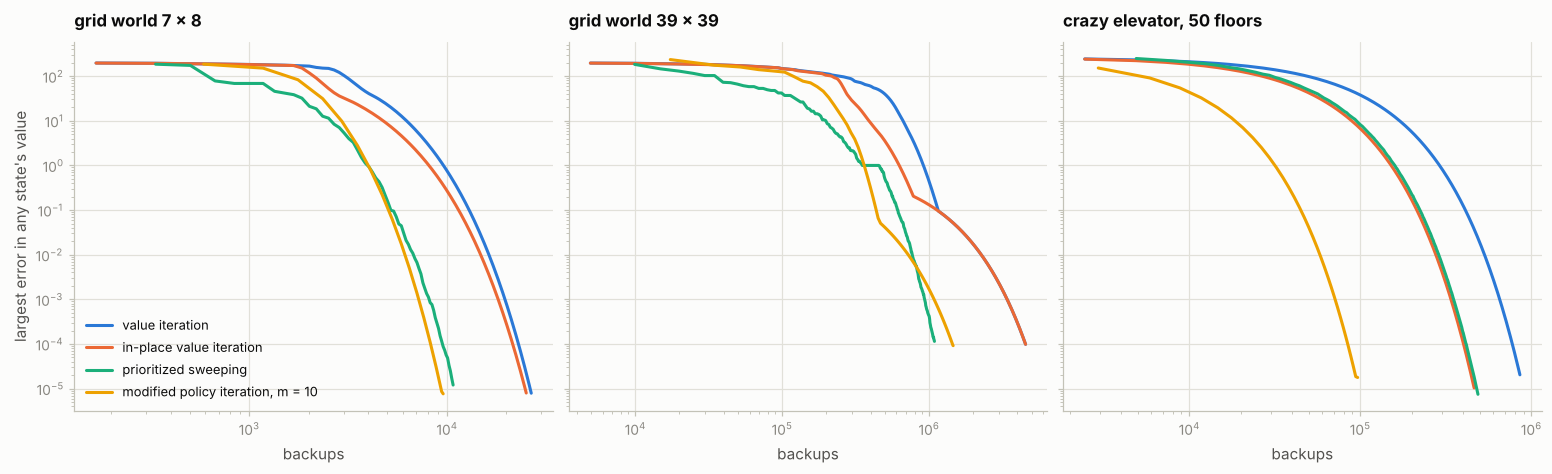

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
shown = ["value iteration", "in-place value iteration", "prioritized sweeping", "modified policy iteration, m = 10"]
for ax, problem in zip(axes, problems):
    for solver, colour in zip(shown, mp.SERIES):
        sol = results[problem, solver]
        ax.plot(sol.history["backups"], np.maximum(sol.history["error"], 1e-7), color=colour, label=solver)
    ax.set(yscale="log", xscale="log", xlabel="backups", title=problem)
axes[0].set_ylabel("largest error in any state's value")
axes[0].legend(loc="lower left", fontsize=8.5)
mp.savefig(fig, "08_error_vs_backups");

In [4]:
vi = {p: results[p, "value iteration"].backups for p in problems}
ratio = pd.DataFrame({p: {s: vi[p] / results[p, s].backups for s in solvers} for p in problems})
pd.options.display.float_format = "{:,.1f}".format
ratio.rename_axis("speed-up over value iteration, in backups")

,grid world 7 × 8,grid world 39 × 39,"crazy elevator, 50 floors"
"speed-up over value iteration, in backups",,,
value iteration,1.0,1.0,1.0
in-place value iteration,1.1,1.0,1.9
prioritized sweeping,2.5,4.2,1.8
"modified policy iteration, m = 10",2.8,3.1,8.9
"modified policy iteration, m = 100",1.5,2.5,26.9


Three observations.

**In-place updates help where everything is connected.** On the elevator every floor leads to every
other, so a value updated early in a sweep is used fifty times before the sweep is over, and
in-place value iteration needs barely half the sweeps. On the grid worlds it gains almost nothing.
There the count is set by a few sticky cells (notebook 6), and a cell that is waiting on *itself*
does not care in which order the others are visited. On the 39 × 39 world, with its walled-in
corner, the count is 918 sweeps either way.

**Prioritized sweeping helps where things are local.** On the grid worlds it needs a quarter to
two fifths of value iteration's backups, because it stops revisiting the large part of the grid
that has long converged and concentrates on the cells that are still moving. On the elevator it
has nothing to work with: every floor is a predecessor of every floor, so every update makes
every other state a little out of date, and the priority queue degenerates into in-place
sweeping with extra bookkeeping.

**Modified policy iteration is the best all-rounder.** It needs about a third of value iteration's
backups on the grids, where on the large one prioritized sweeping edges ahead of it, and a ninth to
a twenty-seventh on the elevator. Its advantage is the one notebook 6 identified: an evaluation
sweep costs one backup per state instead of one per state and action.

## What the stopping rule guarantees

The stopping rule looks at how much the values *changed*, not at how far they are from the truth.
The two differ by a factor that depends on the problem, and with the true optimum at hand it can
be measured.

In [5]:
rows_out = []
for problem, mdp in problems.items():
    sol = results[problem, "value iteration"]
    policy = ml.policy_iteration(mdp).policy
    P_pi, _ = mdp.policy_model(policy)
    idx = np.flatnonzero(mdp.active)
    block = P_pi[idx][:, idx]
    block = block.toarray() if hasattr(block, "toarray") else block
    rho = np.abs(np.linalg.eigvals(block)).max()
    rows_out.append({
        "problem": problem,
        "last change": sol.history["delta"][-1],
        "true error at that point": np.abs(sol.V - optimum[problem]).max(),
        "error / change": np.abs(sol.V - optimum[problem]).max() / sol.history["delta"][-1],
        "γρ / (1 − γρ)": mdp.gamma * rho / (1 - mdp.gamma * rho),
    })
pd.options.display.float_format = "{:,.3g}".format
pd.DataFrame(rows_out).set_index("problem")

,last change,true error at that point,error / change,γρ / (1 − γρ)
problem,,,,
grid world 7 × 8,9.66e-07,7.9e-06,8.17,8.17
grid world 39 × 39,9.94e-07,9.84e-05,99,99
"crazy elevator, 50 floors",9.75e-07,2.04e-05,20.9,20.9


When value iteration stops because the last change was below $10^{-6}$, its values are still off
by 8, 99 and 21 times that. The factor is $\gamma\rho/(1-\gamma\rho)$, with $\rho$ the stickiness
of notebook 6: the remaining error is the sum of all the changes that would still have come. On
the 39 × 39 world, where $\rho = 1$, it reaches the worst case $\gamma/(1-\gamma) = 99$. A
tolerance on the change is therefore a tolerance of up to a hundred times as much on the answer.
For these problems that is still far more precision than the policy needs.

## Solving instead of iterating

The remaining two methods do not creep towards the optimum. They compute it.

**Policy iteration with exact evaluation** replaces the evaluation sweeps by the solution of the
linear system $(I - \gamma P_\pi)V = r_\pi$. It needs a handful of solves and returns the optimal
values to machine precision.

**Linear programming** uses the fact that the optimal value function is the smallest $V$ that
satisfies $V(s) \ge r(s,a) + \gamma \sum_{s'} p(s'|s,a)V(s')$ for every state and action.
Minimising $\sum_s V(s)$ under those constraints hands the whole problem to a general-purpose
solver (here HiGHS, through SciPy).

In [6]:
rows_out = []
for problem, mdp in problems.items():
    start = time.perf_counter()
    exact = ml.policy_iteration(mdp)
    t_pi = time.perf_counter() - start
    lp = ml.linear_programming(mdp)
    fast = results[problem, "modified policy iteration, m = 10"]
    rows_out.append({
        "problem": problem,
        "policy iteration: linear solves": f"{exact.solves}",
        "policy iteration: milliseconds": f"{1e3 * t_pi:.1f}",
        "linear program: constraints": f"{mdp.n_active * mdp.n_actions:,}",
        "linear program: milliseconds": f"{1e3 * lp.seconds:.1f}",
        "linear program: largest difference from policy iteration": f"{np.abs(lp.V - exact.V).max():.0e}",
        "modified policy iteration: milliseconds": f"{1e3 * fast.seconds:.1f}",
        "value iteration: milliseconds": f"{1e3 * results[problem, 'value iteration'].seconds:.1f}",
    })
pd.DataFrame(rows_out).set_index("problem").T

problem,grid world 7 × 8,grid world 39 × 39,"crazy elevator, 50 floors"
policy iteration: linear solves,9,16,3
policy iteration: milliseconds,4.5,37.0,0.8
linear program: constraints,168,"4,952","2,450"
linear program: milliseconds,5.7,316.6,105.2
linear program: largest difference from policy iteration,7e-13,2e-09,8e-12
modified policy iteration: milliseconds,2.9,37.7,1.9
value iteration: milliseconds,7.3,161.8,29.5


All routes arrive at the same value function. At these sizes exact policy iteration is as fast as
anything and has no tolerance to tune, which is why it is the default planner in this package. The
linear program is the slowest route on the two larger problems, but it is a different kind of
tool. Its dual form, which optimises over how often each state-action pair is visited, accepts
side constraints such as "the probability of ending in a pit must stay below 1%", something none
of the iterative methods can accommodate.

## Which planner for which problem

| | few actions, local moves (grid world) | many actions, everything connected (elevator) |
|---|---|---|
| value iteration | baseline | baseline, and expensive: every sweep touches every button |
| in-place sweeps | no gain | about 2 × |
| prioritized sweeping | 2.5 to 4 × | no gain over in-place sweeps |
| modified policy iteration | about 3 × | 9 to 27 × |
| exact policy iteration | a few linear solves | a few linear solves |

The pattern is the same one the report stumbled on with its two planners: what a method costs
depends on the shape of the MDP at least as much as on its size.

Next: [9 · Temporal-difference control](09_td_control.ipynb).